## Module 3: Computational Drug Discovery Project: Cavalitide

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17      # GLP1
L1_fast = 0.015 # GLP1 (fasting)
L1_fed = 0.040  # GLP1 (after meal)
L1 = L1_fast    # the binding experiments were run with fasting-level GLP1


Cavalitide   brute-force Kd = 0.074 nM (SSE = 0.0054) | curve_fit Kd = 0.0770 +/- 0.0045 nM (SSE = 0.0052, R^2 = 0.997)
Semaglutide  brute-force Kd = 0.335 nM (SSE = 0.0047) | curve_fit Kd = 0.3498 +/- 0.0191 nM (SSE = 0.0044, R^2 = 0.997)

Cavalitide binds ~4.5x tighter than semaglutide (Kd 0.077 vs 0.350 nM)


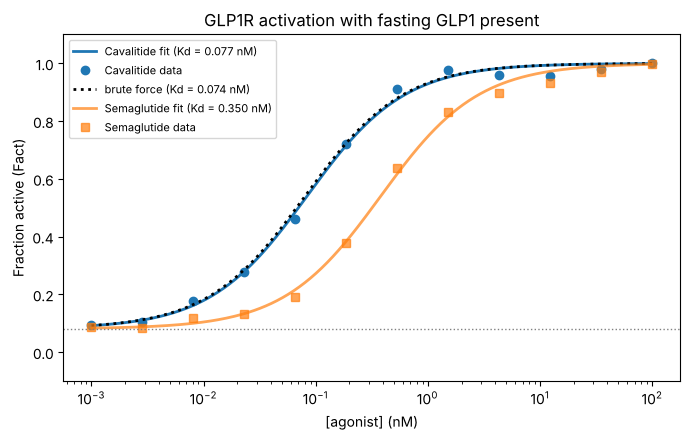

In [2]:
# ---- Task 1: fit Kd for Cavalitide (and re-fit semaglutide for comparison) ----
L2 = np.logspace(-3, 2, 500)   # [nM] smooth grid for plotting model curves

def load(fname):
    d = np.loadtxt(fname, delimiter=",", skiprows=1)
    return d[:, 0], d[:, 1]

def fit_Kd2(L2_data, Fact_data):
    """Fit Kd2 two ways: (1) brute force over a log-spaced grid, (2) scipy curve_fit."""
    # Approach 1: brute force
    Kd2_candidates = np.logspace(-3, 2, 100)   # [nM]
    SSE_brute = np.inf
    for Kd2_try in Kd2_candidates:
        SSE = np.sum((Fact_data - Fact(L1, L2_data, Kd1, Kd2_try))**2)
        if SSE < SSE_brute:
            SSE_brute, Kd2_brute = SSE, Kd2_try
    # Approach 2: curve_fit (gradient-based)
    popt, pcov = curve_fit(lambda x, Kd2: Fact(L1, x, Kd1, Kd2),
                           L2_data, Fact_data, p0=[0.1], bounds=(0, np.inf))
    Kd2_fit, Kd2_se = popt[0], np.sqrt(pcov[0, 0])
    SSE_fit = np.sum((Fact_data - Fact(L1, L2_data, Kd1, Kd2_fit))**2)
    R2 = 1 - SSE_fit / np.sum((Fact_data - Fact_data.mean())**2)
    return dict(brute=Kd2_brute, SSE_brute=SSE_brute, fit=Kd2_fit, se=Kd2_se, SSE_fit=SSE_fit, R2=R2)

cav_L2, cav_Fact = load("cavalitide_data.csv")
sem_L2, sem_Fact = load("semaglutide_data.csv")
cav = fit_Kd2(cav_L2, cav_Fact)
sem = fit_Kd2(sem_L2, sem_Fact)

for name, r in [("Cavalitide", cav), ("Semaglutide", sem)]:
    print(f"{name:12s} brute-force Kd = {r['brute']:.3f} nM (SSE = {r['SSE_brute']:.4f}) | "
          f"curve_fit Kd = {r['fit']:.4f} +/- {r['se']:.4f} nM (SSE = {r['SSE_fit']:.4f}, R^2 = {r['R2']:.3f})")
Kd_cav = cav["fit"]    # <- optimized Kd used in Tasks 2/3
Kd_sem = sem["fit"]
print(f"\nCavalitide binds ~{Kd_sem/Kd_cav:.1f}x tighter than semaglutide (Kd {Kd_cav:.3f} vs {Kd_sem:.3f} nM)")

plt.figure(figsize=(7, 4.5))
l1, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd_cav), lw=2, label=f"Cavalitide fit (Kd = {Kd_cav:.3f} nM)")
plt.semilogx(cav_L2, cav_Fact, "o", c=l1.get_color(), label="Cavalitide data")
plt.semilogx(L2, Fact(L1, L2, Kd1, cav["brute"]), ":", c="k", lw=2, label=f"brute force (Kd = {cav['brute']:.3f} nM)")
l2, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd_sem), lw=2, alpha=0.7, label=f"Semaglutide fit (Kd = {Kd_sem:.3f} nM)")
plt.semilogx(sem_L2, sem_Fact, "s", c=l2.get_color(), alpha=0.7, label="Semaglutide data")
plt.axhline(Fact(L1, 0, Kd1, Kd_cav), ls=":", c="gray", lw=1)   # GLP1-only baseline
plt.ylim(-0.1, 1.1)
plt.xlabel("[agonist] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation with fasting GLP1 present")
plt.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


### Task 1 results and interpretation

**(a) Approach.** We adapted `fit_semaglutide_GLP1R.py` to the Cavalitide data. The model is the two-agonist receptor model, in which native GLP1 (Kd1 = 0.17 nM, held at its fasting level of 0.015 nM, the condition of the binding experiments) and the test agonist compete for GLP1R, and Cavalitide's Kd is the only fitted parameter. We fit it two ways: brute force (100 log-spaced candidates from 0.001 to 100 nM) and `scipy.optimize.curve_fit` (gradient-based). We refit semaglutide with the same code so the two drugs are compared on equal footing.

**(b) Fit quality.** The plot above shows the Cavalitide data (circles) and fitted curve, with the semaglutide data and fit for comparison. The fit tracks the data across the full range: R² = 0.997 and SSE = 0.0052. The curve starts at about 0.08 (the activation from fasting GLP1 alone, L1/(Kd1 + L1)) and saturates at 1. The brute-force and `curve_fit` curves are nearly indistinguishable.

**(c) Fitted Kd.**

| | Kd, `curve_fit` | Kd, brute force | R² |
|---|---|---|---|
| **Cavalitide** | **0.077 ± 0.005 nM** | 0.074 nM | 0.997 |
| Semaglutide | 0.350 ± 0.019 nM | 0.335 nM | 0.997 |

`curve_fit` gives a slightly lower SSE than brute force because the brute-force answer is limited by its grid spacing (about 6% steps), whereas `curve_fit` refines continuously. We use the `curve_fit` value (0.077 nM) for Tasks 2 and 3.

**Interpretation.** A lower Kd means tighter binding. Cavalitide binds GLP1R about **4.5× more tightly** than semaglutide (0.077 vs 0.350 nM), which shifts its dose-response curve to the left. The concentration needed for a half-maximal increase in activation is about 0.08 nM for Cavalitide versus about 0.38 nM for semaglutide, and at 0.5 nM free drug the model predicts 87% active receptors for Cavalitide versus 60% for semaglutide.

*Potential advantages:*
- Less drug is needed in the blood to reach a given receptor activation, which allows a lower dose, less drug to manufacture, and the possibility of reaching high activation even with poor oral bioavailability.
- Cavalitide competes more effectively with native GLP1. At 0.5 nM the predicted activation is nearly the same fasting (0.868) and after a meal (0.871), so receptor activation is more predictable across meals.

*Potential disadvantages:*
- Kd measures binding affinity only. Both drugs saturate at about 100% activation at high concentration, so a lower Kd does not increase the maximum effect, and this dataset says nothing about efficacy beyond receptor occupancy.
- Because Cavalitide activation barely depends on meal-time GLP1, it would blunt the natural fasting-versus-fed modulation of the receptor, and stronger activation could increase on-target side effects. We did not model this; it would need clinical data.
- Binding to GLP1R says nothing about selectivity (off-target binding), stability, or oral absorption. Those are tested in later tasks and in experiments we do not have.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

### Task 2 code
**PK model (semaglutidePK.py → `solve_ivp`).** The explicit Euler loop is replaced with `scipy.integrate.solve_ivp`. The dose is an instantaneous jump in the depot amount, so the solver is restarted at each dose and the state is carried forward. Ozempic is run for 15 weekly doses (instead of 8) so both products span the same ~100-day window.

In [ ]:
# ---- Pharmacokinetic model ----
products = {
    'Ozempic':    dict(Favailable=0.89, ka=0.029,  D=2.0,  interval=168, n_doses=15,  depot='subcutaneous'),
    'Wegovy':     dict(Favailable=0.01, ka=0.0029, D=25.0, interval=24,  n_doses=100, depot='gut (oral)'),
    'Cavalitide': dict(Favailable=0.01, ka=0.006,  D=25.0, interval=24,  n_doses=100, depot='gut (oral)'),
}
# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol (semaglutide; Cavalitide assumed the same)
Ffree = 0.01    # fraction free in blood (rest bound to albumin)

def simulate(Favailable, ka, D, interval, n_doses, dt_out=0.5, **_):
    """Repeated dosing every `interval` h. Returns time (h), depot amount (mg),
    and FREE blood concentration (nM). Each interval is integrated with solve_ivp;
    the dose is added to the depot at the start of the interval."""
    def ODEfunc(t, y):
        Asc, Cc = y
        dAsc = -ka*Asc             # depot amount (mg)
        dCc = ka*Asc/V - ke*Cc     # blood concentration (mg/L)
        return [dAsc, dCc]
    t_all, A_all, C_all = [], [], []
    y = [0.0, 0.0]
    for i in range(n_doses):
        y[0] += Favailable*D       # absorbed fraction of dose enters the depot
        t_eval = np.arange(i*interval, (i+1)*interval + dt_out/2, dt_out)
        sol = solve_ivp(ODEfunc, (i*interval, (i+1)*interval), y, t_eval=t_eval,
                        method='LSODA', rtol=1e-8, atol=1e-12)
        t_all.append(sol.t); A_all.append(sol.y[0]); C_all.append(sol.y[1])
        y = [sol.y[0, -1], sol.y[1, -1]]   # carry state into next interval
    t = np.concatenate(t_all)
    A = np.concatenate(A_all)
    C_nM = np.concatenate(C_all) * 1e-3 / MW * 1e9   # mg/L -> nmol/L (total)
    return t, A, Ffree*C_nM

def ss_mean_free(Favailable, D, interval, **_):
    """Analytic steady-state AVERAGE free concentration (nM): F*D / (ke*V*interval).
    Note: independent of ka -- absorption rate only changes how fast you get there and the ripple."""
    return Ffree * (Favailable*D/(ke*V*interval)) * 1e-3 / MW * 1e9

def dose_for_target(target_nM, Favailable, interval, **_):
    """Dose (mg) that gives a target steady-state mean free concentration."""
    return target_nM / ss_mean_free(Favailable, 1.0, interval)


**2.1** Ozempic (weekly subcutaneous) vs Wegovy (daily pill)

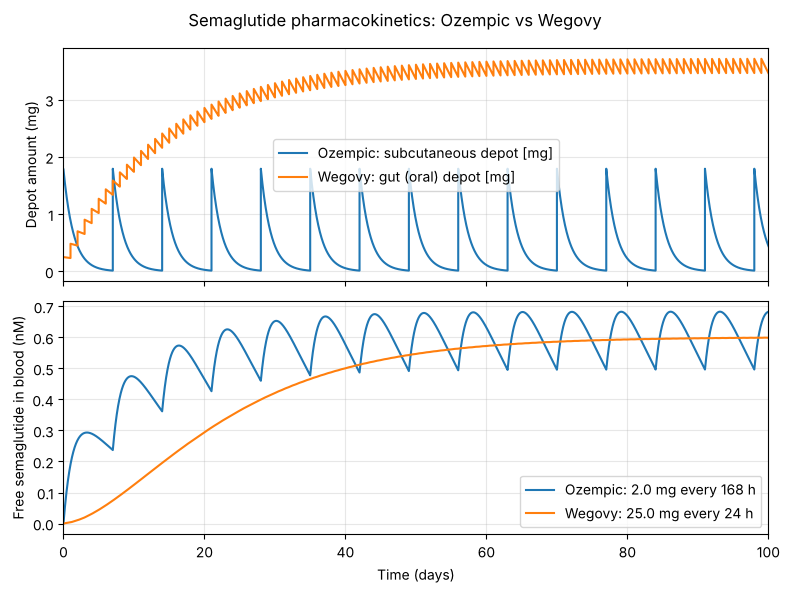

Ozempic  final-interval free conc: mean 0.611 nM, min 0.497, max 0.683  (analytic mean 0.612 nM)
Wegovy   final-interval free conc: mean 0.599 nM, min 0.599, max 0.599  (analytic mean 0.601 nM)


In [4]:
# ---- Task 2.1: Ozempic (weekly SC) vs Wegovy (daily pill) ----
sims = {k: simulate(**products[k]) for k in ['Ozempic', 'Wegovy']}

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for k, (t, A, C) in sims.items():
    ax[0].plot(t/24, A, label=f"{k}: {products[k]['depot']} depot [mg]")
    ax[1].plot(t/24, C, label=f"{k}: {products[k]['D']} mg every {products[k]['interval']} h")
ax[0].set_ylabel("Depot amount (mg)")
ax[1].set_ylabel("Free semaglutide in blood (nM)")
ax[1].set_xlabel("Time (days)")
ax[1].set_xlim(0, 100)
for a in ax:
    a.legend(); a.grid(alpha=0.3)
fig.suptitle("Semaglutide pharmacokinetics: Ozempic vs Wegovy")
plt.tight_layout()
plt.show()

for k, (t, A, C) in sims.items():
    last = t >= t[-1] - products[k]['interval']
    print(f"{k:8s} final-interval free conc: mean {C[last].mean():.3f} nM, min {C[last].min():.3f}, max {C[last].max():.3f}"
          f"  (analytic mean {ss_mean_free(**products[k]):.3f} nM)")


**Interpretation (2.1).** Ozempic and Wegovy reach nearly the same average free concentration, about **0.6 nM**, but with very different shapes:
- **Ozempic (weekly injection)** produces a sawtooth that, at steady state, swings between about 0.50 and 0.68 nM. The ripple is large because the dosing interval (7 days) is comparable to the drug's elimination half-life (ln 2 / ke ≈ 7.4 days).
- **Wegovy (daily pill)** gives an almost flat profile, because doses are small relative to the half-life, but it approaches steady state more slowly (90% of steady state around day 48). The slow absorption (ka = 0.0029 1/h) delays the rise.
- The averages match because the steady-state mean is F·D/(ke·V·interval), which depends only on the amount absorbed per unit time. Ozempic absorbs 0.89 × 2 mg per week ≈ 0.25 mg/day, and Wegovy absorbs 0.01 × 25 mg = 0.25 mg/day. The pill needs about 100× more drug in the tablet because only 1% is absorbed.

**2.2** Cavalitide (daily pill, ka = 0.006 1/h)

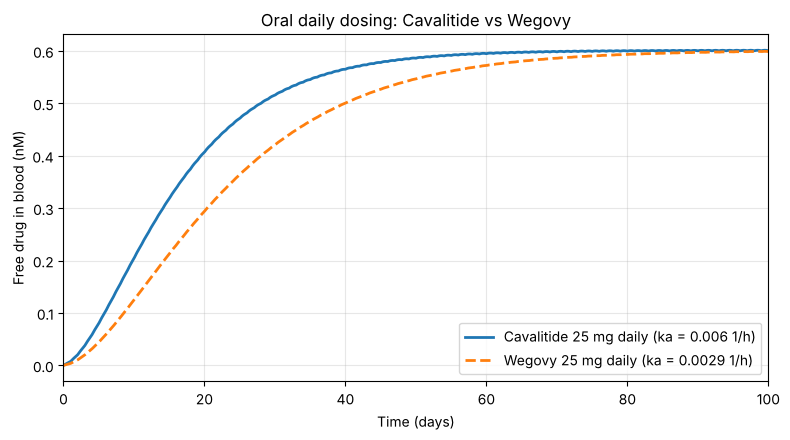

Cavalitide steady-state mean = 0.601 nM; reaches 90% of steady state at day 34.0 (Wegovy: day 47.9)


In [5]:
# ---- Task 2.2: add Cavalitide (daily pill, ka = 0.006 1/h) ----
t_c, A_c, C_c = simulate(**products['Cavalitide'])
t_w, A_w, C_w = sims['Wegovy']

plt.figure(figsize=(8, 4.5))
plt.plot(t_c/24, C_c, lw=2, label="Cavalitide 25 mg daily (ka = 0.006 1/h)")
plt.plot(t_w/24, C_w, "--", lw=2, label="Wegovy 25 mg daily (ka = 0.0029 1/h)")
plt.xlabel("Time (days)"); plt.ylabel("Free drug in blood (nM)")
plt.title("Oral daily dosing: Cavalitide vs Wegovy")
plt.xlim(0, 100); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

def time_to_frac(t, C, frac=0.9):
    return t[np.argmax(C >= frac*C[-1])]/24
print(f"Cavalitide steady-state mean = {C_c[-48:].mean():.3f} nM; reaches 90% of steady state at day {time_to_frac(t_c, C_c):.1f} "
      f"(Wegovy: day {time_to_frac(t_w, C_w):.1f})")


**Interpretation (2.2).** With the same dose (25 mg), schedule, and bioavailability as Wegovy but about twice the absorption rate, Cavalitide reaches the same steady state (about 0.60 nM) **faster**: 90% of steady state by about day 34, versus about day 48 for Wegovy. A faster ka therefore shortens the time to therapeutic levels, but does not change the steady-state level itself. The profile is still essentially flat across each day.

**2.3** Dose optimization to ~0.5 nM

Dose needed for 0.5 nM with daily dosing: D = 20.8 mg (was 25.0 mg)


Simulated steady state at day 100 with D = 20.8 mg: mean 0.500 nM


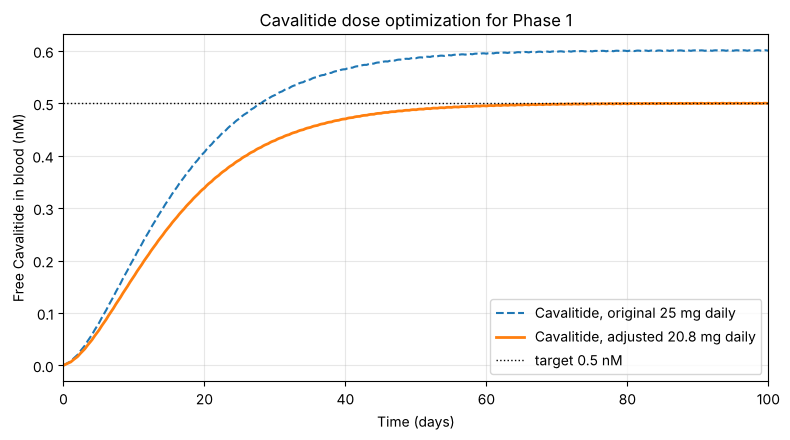

In [6]:
# ---- Task 2.3: adjust dosing to reach ~0.5 nM at steady state ----
# Steady-state mean = F*D/(ke*V*interval) does NOT depend on ka, so the lever is the dose rate (D/interval).
target = 0.5   # nM
D_opt = dose_for_target(target, products['Cavalitide']['Favailable'], products['Cavalitide']['interval'])
print(f"Dose needed for {target} nM with daily dosing: D = {D_opt:.1f} mg (was {products['Cavalitide']['D']} mg)")

cav_opt = dict(products['Cavalitide'], D=round(D_opt, 1))
t_o, A_o, C_o = simulate(**cav_opt)
print(f"Simulated steady state at day 100 with D = {cav_opt['D']} mg: mean {C_o[-48:].mean():.3f} nM")

plt.figure(figsize=(8, 4.5))
plt.plot(t_c/24, C_c, "--", lw=1.5, label="Cavalitide, original 25 mg daily")
plt.plot(t_o/24, C_o, lw=2, label=f"Cavalitide, adjusted {cav_opt['D']} mg daily")
plt.axhline(target, c="k", ls=":", lw=1, label="target 0.5 nM")
plt.xlabel("Time (days)"); plt.ylabel("Free Cavalitide in blood (nM)")
plt.title("Cavalitide dose optimization for Phase 1")
plt.xlim(0, 100); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()


**Interpretation (2.3).** *What we changed:* the daily dose, from 25 mg to **20.8 mg** (a 17% reduction), keeping the once-daily pill schedule. The simulated steady state is 0.500 nM.

*Why:* the steady-state mean concentration is F·D/(ke·V·interval). It is proportional to dose and **does not depend on ka**, so the higher absorption rate cannot be used to hit 0.5 nM; the dose has to be lowered (or the interval lengthened). We kept the interval at 24 h because a once-daily pill is simple for patients and gives a flat profile, so the dose was the natural adjustment. We solved for it directly (D = target / concentration per mg) rather than by trial and error, and then verified it by simulation. A lower dose also means less drug per patient, which is a potential cost and exposure benefit.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


### Task 3 code
**3.1** Combined PKPD (`cavalitidePKPD.py`): the PK model gives free Cavalitide(t), which feeds the ligand-receptor model (fitted Kd from Task 1, with fasting or post-meal GLP1 as the background agonist).

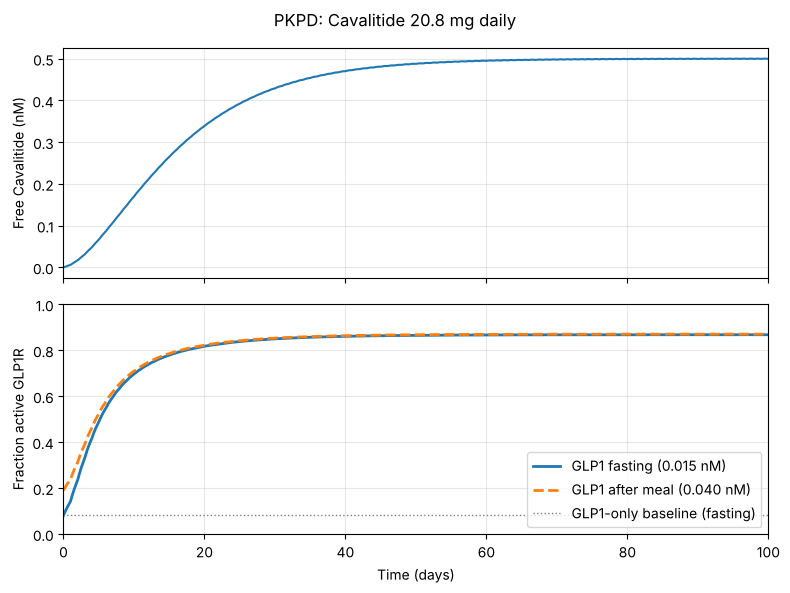

Fraction active GLP1R at day 100 (Phase 1 dose, fasting GLP1): 0.868


In [7]:
# ---- Task 3.1: combined PKPD model (cavalitidePKPD) ----
def cavalitide_PKPD(L1_glp1, Kd2=None, **dosing):
    """PK -> free Cavalitide(t) -> receptor activation Fact(t) using the fitted Kd and GLP1 background."""
    Kd2 = Kd_cav if Kd2 is None else Kd2
    t, A, C = simulate(**dosing)
    return t, C, Fact(L1_glp1, C, Kd1, Kd2)

t1, C1, F1 = cavalitide_PKPD(L1_fast, **cav_opt)   # Phase 1 dosing (0.5 nM)
_, _, F1_fed = cavalitide_PKPD(L1_fed, **cav_opt)

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t1/24, C1, c="C0"); ax[0].set_ylabel("Free Cavalitide (nM)")
ax[1].plot(t1/24, F1, lw=2, label="GLP1 fasting (0.015 nM)")
ax[1].plot(t1/24, F1_fed, lw=2, ls="--", label="GLP1 after meal (0.040 nM)")
ax[1].axhline(Fact(L1_fast, 0, Kd1, Kd_cav), c="gray", ls=":", lw=1, label="GLP1-only baseline (fasting)")
ax[1].set_ylabel("Fraction active GLP1R"); ax[1].set_xlabel("Time (days)")
ax[1].set_ylim(0, 1); ax[1].set_xlim(0, 100); ax[1].legend(loc="lower right")
for a in ax: a.grid(alpha=0.3)
fig.suptitle(f"PKPD: Cavalitide {cav_opt['D']} mg daily")
plt.tight_layout(); plt.show()
print(f"Fraction active GLP1R at day 100 (Phase 1 dose, fasting GLP1): {F1[-48:].mean():.3f}")


**Interpretation (3.1).** At the Phase 1 dose (20.8 mg daily, 0.5 nM free drug), receptor activation rises from the GLP1-only baseline (about 8% fasting, 19% after a meal) to a steady state of about **87%** active GLP1R. Two features stand out:
- **Activation reaches steady state faster than concentration does** (90% of its final value by about day 15, versus about day 34 for concentration). Activation is a saturating function of concentration, so most of the benefit appears when concentration is only about half of its final value.
- **Meals barely matter.** Fasting and post-meal GLP1 give nearly identical activation (0.868 vs 0.871) because Cavalitide occupies most receptors.

**3.2** Dose tuned for ~90% active receptors

Need 0.686 nM free Cavalitide -> daily dose D = 28.5 mg (Phase 1: 20.8 mg)
Day-100 free Cavalitide = 0.685 nM, fraction active GLP1R = 0.900
Reaches 90% of its day-100 activation at day 13.3


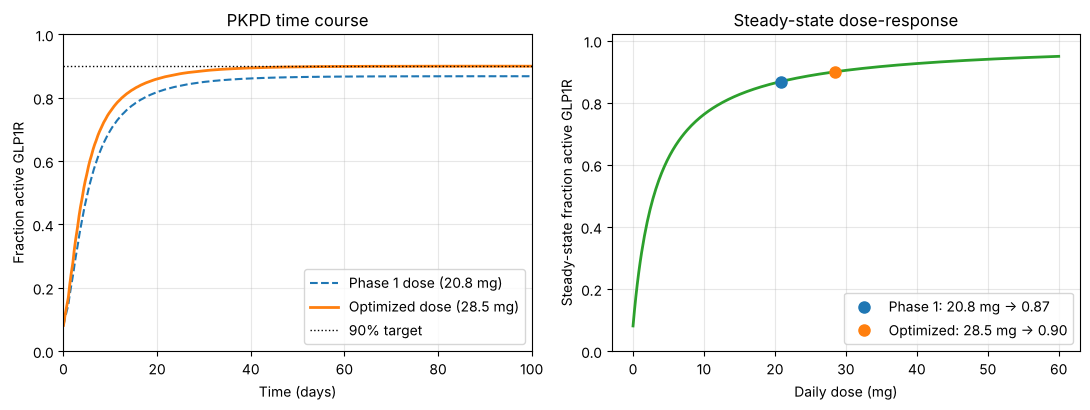

In [8]:
# ---- Task 3.2: tune dose for ~90% active receptors at steady state ----
target_F = 0.90
# invert Fact(L1, L2) = target for the free Cavalitide concentration needed
C_needed = brentq(lambda c: Fact(L1_fast, c, Kd1, Kd_cav) - target_F, 1e-6, 1e3)
D_90 = round(dose_for_target(C_needed, products['Cavalitide']['Favailable'], products['Cavalitide']['interval']), 1)
print(f"Need {C_needed:.3f} nM free Cavalitide -> daily dose D = {D_90} mg (Phase 1: {cav_opt['D']} mg)")

cav_90 = dict(products['Cavalitide'], D=D_90)
t2, C2, F2 = cavalitide_PKPD(L1_fast, **cav_90)
print(f"Day-100 free Cavalitide = {C2[-48:].mean():.3f} nM, fraction active GLP1R = {F2[-48:].mean():.3f}")
print(f"Reaches 90% of its day-100 activation at day {t2[np.argmax(F2 >= 0.9*F2[-1])]/24:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(t1/24, F1, "--", lw=1.5, label=f"Phase 1 dose ({cav_opt['D']} mg)")
ax[0].plot(t2/24, F2, lw=2, label=f"Optimized dose ({D_90} mg)")
ax[0].axhline(target_F, c="k", ls=":", lw=1, label="90% target")
ax[0].set_xlabel("Time (days)"); ax[0].set_ylabel("Fraction active GLP1R")
ax[0].set_ylim(0, 1); ax[0].set_xlim(0, 100); ax[0].grid(alpha=0.3); ax[0].legend(loc="lower right")
ax[0].set_title("PKPD time course")

# dose-response at steady state: where the two doses sit on the Fact curve
Dgrid = np.linspace(0, 60, 300)
Css = np.array([ss_mean_free(products['Cavalitide']['Favailable'], d, 24) for d in Dgrid])
ax[1].plot(Dgrid, Fact(L1_fast, Css, Kd1, Kd_cav), c="C2", lw=2)
for d, lab in [(cav_opt['D'], "Phase 1"), (D_90, "Optimized")]:
    f = Fact(L1_fast, ss_mean_free(products['Cavalitide']['Favailable'], d, 24), Kd1, Kd_cav)
    ax[1].plot(d, f, "o", ms=8, label=f"{lab}: {d} mg -> {f:.2f}")
ax[1].set_xlabel("Daily dose (mg)"); ax[1].set_ylabel("Steady-state fraction active GLP1R")
ax[1].set_ylim(0, 1.02); ax[1].grid(alpha=0.3); ax[1].legend(loc="lower right")
ax[1].set_title("Steady-state dose-response")
plt.tight_layout(); plt.show()


**Interpretation (3.2).** *What we changed:* only the daily dose, from 20.8 mg to **28.5 mg** (+37%), with the once-daily schedule unchanged. Reaching 90% activation requires 0.686 nM free Cavalitide, and the simulation gives 0.900 fractional activation at day 100.

*Clinical meaning:*
- Going from 87% to 90% active receptors cuts the fraction of inactive receptors from about 13% to 10% (roughly a 24% reduction), which may mean a stronger and more consistent therapeutic effect if weight loss tracks receptor activation (not modeled here).
- The dose-response plot shows **strongly diminishing returns**: 37% more drug buys only 3 percentage points of activation. Phase 2 should therefore weigh the small efficacy gain against tolerability, cost, and safety, since the steeper part of the curve (below about 10 mg) is where dose matters most. Whether the extra activation is worth it is an empirical question for the trial.

**3.3** Comparison with oral semaglutide (same PK assumptions)

In [9]:
# ---- Task 3.3: how does this compare with oral semaglutide (same PK assumptions)? ----
Ks = Kd_sem
F_sem_25 = Fact(L1_fast, ss_mean_free(products['Wegovy']['Favailable'], 25.0, 24), Kd1, Ks)
C90_sem = brentq(lambda c: Fact(L1_fast, c, Kd1, Ks) - 0.90, 1e-6, 1e3)
D90_sem = dose_for_target(C90_sem, products['Wegovy']['Favailable'], 24)
print(f"Oral semaglutide 25 mg daily (Wegovy): steady-state fraction active GLP1R = {F_sem_25:.3f}")
print(f"Oral semaglutide would need {C90_sem:.2f} nM free drug (~{D90_sem:.0f} mg daily) for 90% activation")
print(f"Cavalitide needs {C_needed:.2f} nM free drug ({D_90} mg daily) -> {D90_sem/D_90:.1f}x less drug for the same activation")


Oral semaglutide 25 mg daily (Wegovy): steady-state fraction active GLP1R = 0.644
Oral semaglutide would need 3.12 nM free drug (~130 mg daily) for 90% activation
Cavalitide needs 0.69 nM free drug (28.5 mg daily) -> 4.5x less drug for the same activation


**Interpretation (3.3).** Under identical PK assumptions, a 25 mg daily Wegovy dose gives only about 64% active receptors, and semaglutide would need roughly 130 mg daily to reach 90%, about 4.5× the Cavalitide dose. This is the practical benefit of Cavalitide's tighter binding: the same receptor activation from much less drug, which matters most for a pill with only 1% bioavailability.

## Conclusions:

Within the limits of the model, Cavalitide looks like a promising competitor to semaglutide, and its edge comes mainly from stronger binding:

- **Higher affinity.** Cavalitide's fitted Kd (0.077 nM) is about 4.5× lower than semaglutide's (0.350 nM), so it activates GLP1R at much lower concentrations.
- **More activation from the same or less drug.** At the same 25 mg daily dose and PK, steady-state activation is about 89% for Cavalitide versus 64% for oral semaglutide. Semaglutide would need about 130 mg daily to reach 90%, whereas Cavalitide needs 28.5 mg.
- **Faster onset.** Its higher absorption rate brings the pill to steady state in about 34 days versus about 48 for Wegovy, though this does not change the steady-state level.
- **Versus injectable Ozempic.** Cavalitide gives a flat daily profile without a weekly injection and without the peak-to-trough swing of about 0.50–0.68 nM, at the cost of a daily rather than weekly dose and (in our assumptions) 1% oral bioavailability.
- **Dosing flexibility.** Because activation saturates, Phase 1 (0.5 nM, 20.8 mg, about 87% activation) and Phase 2 (28.5 mg, 90%) can be tuned with modest dose changes, and the dose-response curve shows where extra drug stops paying off.

These conclusions hold only if Cavalitide's real PK resembles the assumptions we made and if receptor activation translates into weight loss with acceptable tolerability. Those are the main questions for actual trials.

## Limitations and Future Work:

**Limitations**
- **Assumed PK.** We were only given Cavalitide's absorption rate (ka). Bioavailability (1%), elimination rate, volume of distribution, plasma protein binding (1% free), and molecular weight (4113.6 g/mol, semaglutide's) were all copied from semaglutide. Cavalitide is described as a small molecule, so a real molecular weight would be far lower, which would change the nM conversion substantially. Its real elimination and bioavailability could also differ, and the dosing results (20.8 mg, 28.5 mg) scale directly with these.
- **Simple PK model.** One-compartment model with a single depot, first-order absorption and elimination, and no variability between patients (weight, genetics, gut transit, food effects, adherence).
- **Simple PD model.** One receptor, one binding site, equilibrium binding, and fixed GLP1 levels (either fasting or after a meal, not changing over time). We ignore receptor desensitization and internalization, signaling downstream of the receptor, the second incretin pathway (GIP), and the difference between binding and efficacy (a high-affinity ligand is not necessarily more efficacious).
- **Limited data.** The Kd comes from 12 binding measurements in a single experiment with fixed GLP1. We report a standard error (±0.005 nM) but have not tested other model forms (such as a Hill slope) or replicate experiments.
- **Activation is not a clinical endpoint.** We predict receptor activation, not weight loss, tolerability, selectivity, safety, or cost.

**Future work**
- Measure Cavalitide's actual PK (animal then Phase 1 data) and refit ka, ke, V, F, and protein binding, ideally as a population PK model that captures patient variability.
- Run a sensitivity analysis or Monte Carlo simulation over uncertain parameters (Kd, F, ke) to put error bars on the predicted dose and activation.
- Replace the fixed GLP1 level with a meal-driven GLP1 time course, and test whether Cavalitide's near-complete occupancy is desirable.
- Link receptor activation to downstream signaling and to weight-loss outcomes (a full QSP model), and add selectivity data (e.g., GIPR) and dose-dependent side effects to find the best dose for Phase 2.
- Repeat the binding experiment with replicates and different GLP1 concentrations to check the competition model.

## AI Usage Statement:


## GitHub Repository Link:

[Paste your team's repository URL here]

The repository should contain this notebook, `cavalitide_data.csv`, `semaglutide_data.csv`, and the scripts `fit_cavalitide_GLP1R.py` (Task 1), `cavalitidePK.py` (Task 2), and `cavalitidePKPD.py` (Task 3).

## References:

1. Saucerman, J. *BME 2315 Module 3 lectures 1–3: Computational drug discovery* (course slides, Fall 2026). Source of the ligand-receptor model, the fitting methods (brute force, steepest descent / `curve_fit`), the GLP1 and Kd values, and the project description.
2. Lau J, et al. Discovery of the once-weekly glucagon-like peptide-1 (GLP-1) analogue semaglutide. *J Med Chem.* 2015;58(18):7370. https://pubs.acs.org/jmcmar/article/58/18/7370/1339277/ (cited in Lecture 2 for GLP1/semaglutide binding).
3. Brandt SJ, et al. Incretin-based agonists, antagonists, and dual-action drugs. *Peptides.* 2018. https://www.sciencedirect.com/science/article/pii/S0196978117303960 (cited in Lecture 1 for agonist/antagonist mechanisms).
4. Tschöp MH, et al. *Diabetologia.* 2023. https://pubmed.ncbi.nlm.nih.gov/37209227/ (cited in Lecture 1 for how incretin drugs work).

## NOTES FROM YOUR TEAM:

## QUESTIONS FOR YOUR TA: